# Customer Churn Prediction

## Project Overview
This project builds an end-to-end machine learning workflow to predict customer churn for a telecommunications company.

The analysis uses the **IBM Telco Customer Churn** dataset provided with this project. It contains **7,043 customers and 21 columns**, including customer demographics, subscribed services, contract information, charges, and the target variable `Churn`.

### Objectives
- Inspect and clean the dataset.
- Explore factors associated with customer churn.
- Prepare numerical and categorical features for machine learning.
- Train and compare Logistic Regression, Random Forest, and XGBoost classifiers.
- Evaluate models with precision, recall, F1-score, ROC-AUC, confusion matrices, and ROC curves.
- Interpret the model and translate the results into business-oriented conclusions.

## 1. Imports

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

## 2. Load the Dataset

In [2]:
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Initial Data Exploration

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("\nTarget distribution:")
print(df["Churn"].value_counts())
print("\nTarget distribution (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Duplicate rows: 0
Duplicate customer IDs: 0

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target distribution (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### Initial observations
The target is moderately imbalanced: about **26.5%** of customers churned. Therefore, accuracy alone is not sufficient for model evaluation. Recall, precision, F1-score, and ROC-AUC are also considered.

## 4. Data Cleaning

In [6]:
data = df.copy()

# TotalCharges is stored as text because a small number of rows contain blank strings.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

print("Missing values after conversion:")
print(data.isna().sum()[data.isna().sum() > 0])

Missing values after conversion:
TotalCharges    11
dtype: int64


There are 11 missing `TotalCharges` values after conversion. Rather than dropping those customers, the modeling pipeline imputes missing numerical values with the median. This keeps the preprocessing reproducible and prevents information from the test set from leaking into training.

## 5. Exploratory Data Analysis

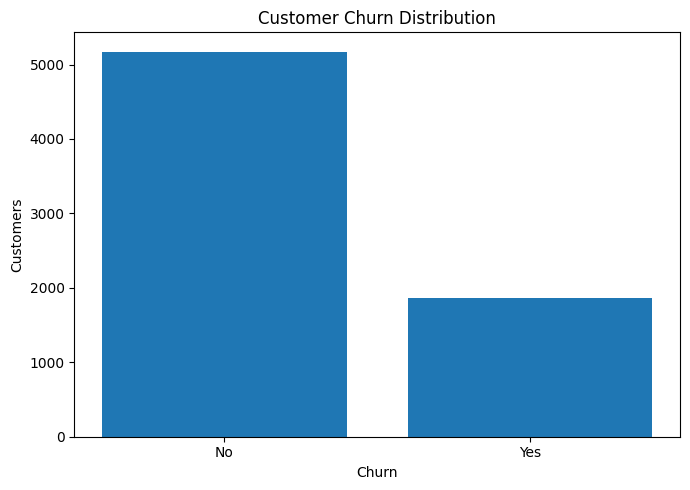

In [7]:
churn_counts = data["Churn"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64


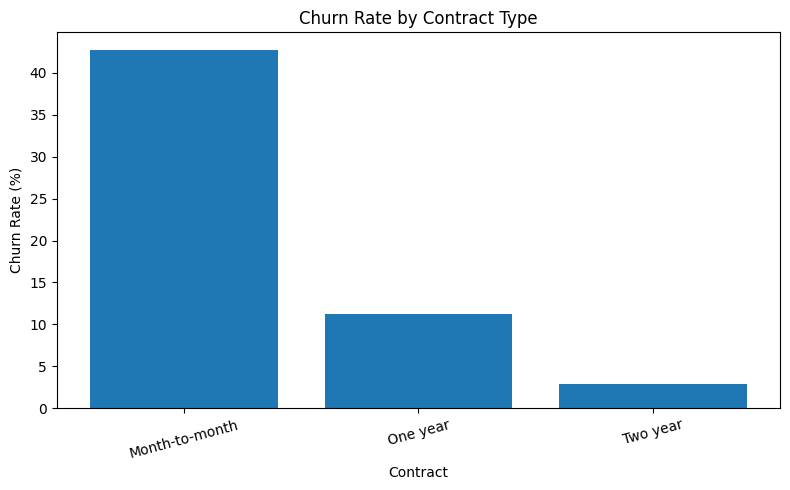

In [8]:
contract_churn = (
    pd.crosstab(data["Contract"], data["Churn"], normalize="index")["Yes"] * 100
).sort_values(ascending=False)

print(contract_churn.round(2))

plt.figure(figsize=(8, 5))
plt.bar(contract_churn.index, contract_churn.values)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Yes, dtype: float64


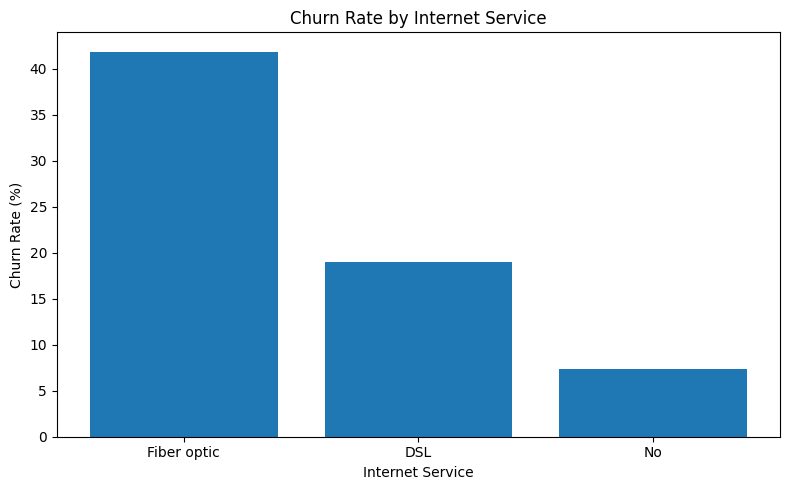

In [9]:
internet_churn = (
    pd.crosstab(data["InternetService"], data["Churn"], normalize="index")["Yes"] * 100
).sort_values(ascending=False)

print(internet_churn.round(2))

plt.figure(figsize=(8, 5))
plt.bar(internet_churn.index, internet_churn.values)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

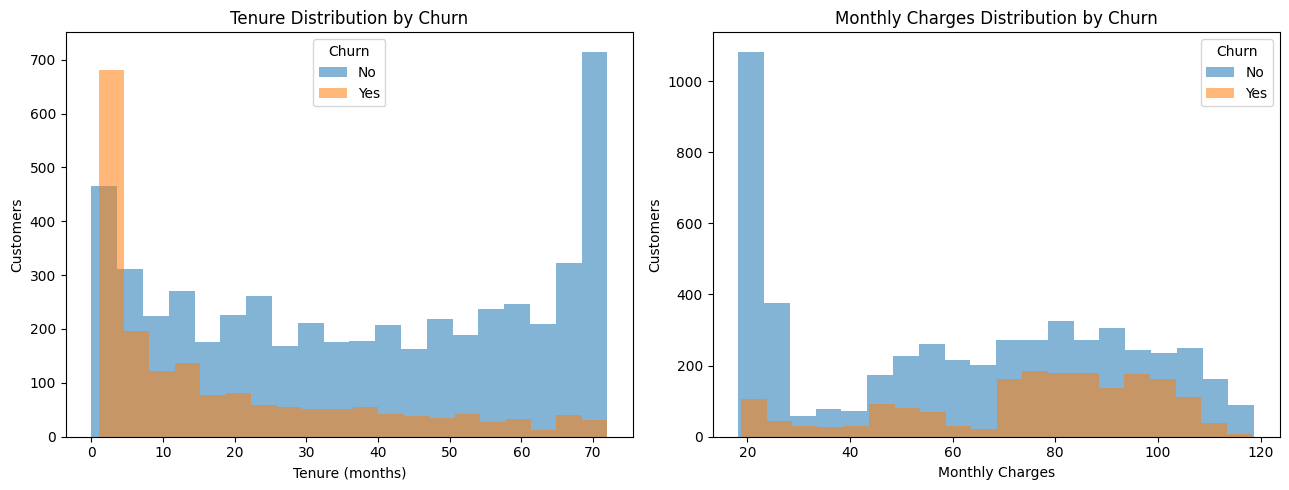

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for churn_value, group in data.groupby("Churn"):
    axes[0].hist(group["tenure"], bins=20, alpha=0.55, label=churn_value)
axes[0].set_title("Tenure Distribution by Churn")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Customers")
axes[0].legend(title="Churn")

for churn_value, group in data.groupby("Churn"):
    axes[1].hist(group["MonthlyCharges"], bins=20, alpha=0.55, label=churn_value)
axes[1].set_title("Monthly Charges Distribution by Churn")
axes[1].set_xlabel("Monthly Charges")
axes[1].set_ylabel("Customers")
axes[1].legend(title="Churn")

plt.tight_layout()
plt.show()

### EDA findings
- Month-to-month contracts have a substantially higher churn rate than one- and two-year contracts.
- Fiber-optic customers show a higher churn rate than DSL customers or customers without internet service.
- Churn is also related to tenure and monthly charges, which makes these useful predictive features.

## 6. Feature Preparation and Preprocessing

In [11]:
X = data.drop(columns=["Churn", "customerID"])
y = data["Churn"].map({"No": 0, "Yes": 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [12]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

`customerID` is removed because it is an identifier rather than a meaningful predictive feature.

The preprocessing is placed inside a scikit-learn `Pipeline`. Numerical variables are median-imputed and standardized; categorical variables are imputed and one-hot encoded. Fitting these transformations only on the training data helps avoid data leakage.

## 7. Train/Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Training churn rate:", round(y_train.mean(), 4))
print("Test churn rate:", round(y_test.mean(), 4))

Training samples: 5634
Test samples: 1409
Training churn rate: 0.2654
Test churn rate: 0.2654


## 8. Train Classification Models

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipeline
    predictions[name] = (y_pred, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
1,XGBoost,0.8013,0.6556,0.5294,0.5858,0.8415
2,Random Forest,0.7814,0.6170,0.4652,0.5305,0.8217


## 9. Model Evaluation

For churn prediction, **recall** measures how many actual churners are identified, while **precision** measures how many predicted churners actually churn. **F1-score** balances the two. **ROC-AUC** evaluates ranking quality across classification thresholds.

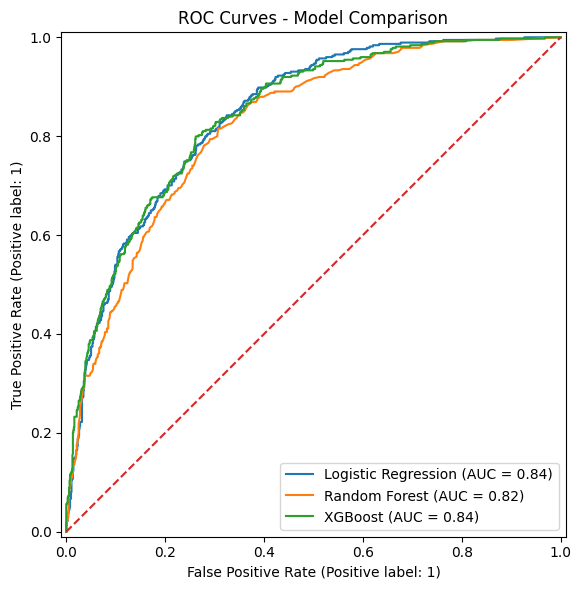

In [15]:
plt.figure(figsize=(8, 6))
ax = plt.gca()

for name in fitted_models:
    y_pred, y_prob = predictions[name]
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curves - Model Comparison")
plt.tight_layout()
plt.show()

In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_pred, best_prob = predictions[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No Churn", "Churn"]))

cm = confusion_matrix(y_test, best_pred)
cm

Selected model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



array([[926, 109],
       [165, 209]])

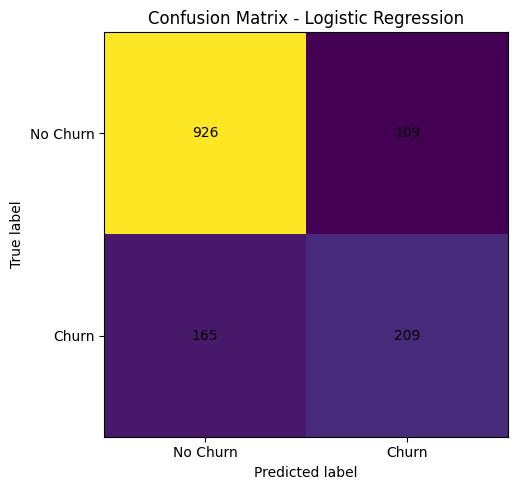

In [17]:
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])

for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")

plt.tight_layout()
plt.show()

### Model comparison
With the fixed 80/20 stratified split used in this notebook, Logistic Regression and XGBoost perform very similarly in ROC-AUC. Logistic Regression is selected by the notebook's ROC-AUC ordering and also offers straightforward coefficient-based interpretation.

The selected model should not be interpreted as universally superior: performance can vary across resampling folds, hyperparameters, thresholds, and business costs.

## 10. Model Interpretation

In [18]:
logistic_pipeline = fitted_models["Logistic Regression"]

feature_names = logistic_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = logistic_pipeline.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
coef_df["AbsoluteCoefficient"] = coef_df["Coefficient"].abs()

top_features = (
    coef_df.nlargest(15, "AbsoluteCoefficient")
    .sort_values("Coefficient")
)

top_features[["Feature", "Coefficient"]]

,Feature,Coefficient
1,num__tenure,-1.241319
38,cat__Contract_Two year,-0.772261
15,cat__InternetService_DSL,-0.652406
2,num__MonthlyCharges,-0.596392
39,cat__PaperlessBilling_No,-0.343260
22,cat__OnlineBackup_No internet service,-0.301082
19,cat__OnlineSecurity_No internet service,-0.301082
17,cat__InternetService_No,-0.301082
28,cat__TechSupport_No internet service,-0.301082
31,cat__StreamingTV_No internet service,-0.301082


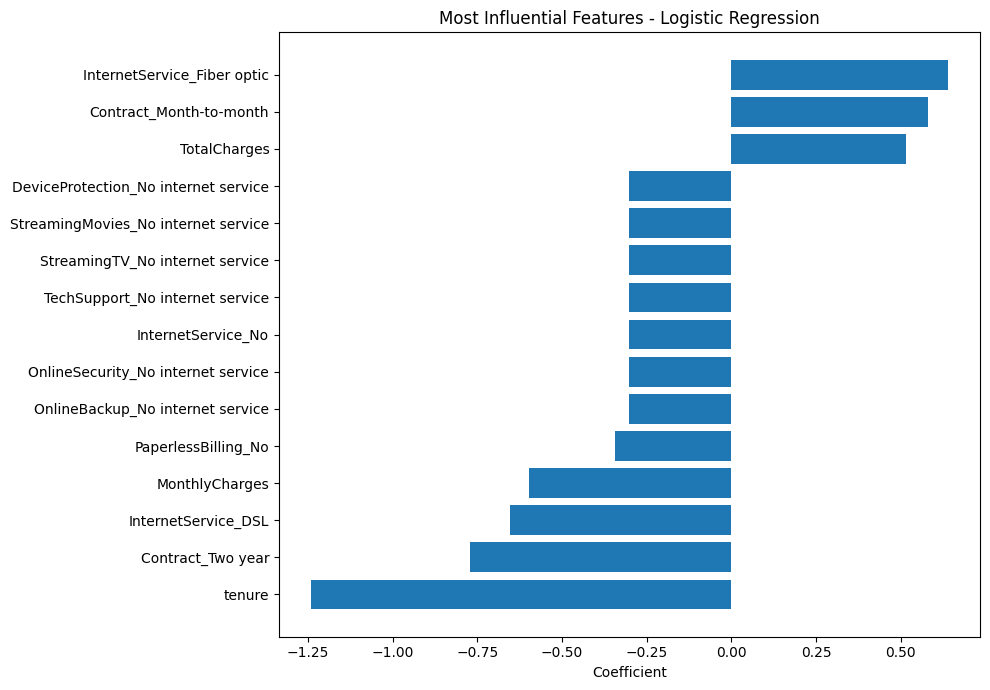

In [19]:
labels = (
    top_features["Feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
)

plt.figure(figsize=(10, 7))
plt.barh(labels, top_features["Coefficient"])
plt.title("Most Influential Features - Logistic Regression")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

Positive logistic-regression coefficients increase the model's estimated log-odds of churn, while negative coefficients reduce them, conditional on the other encoded features. These coefficients describe associations in this predictive model and should **not** be interpreted as causal effects.

## 11. Business Interpretation

In [20]:
print("Overall churn rate:", f"{y.mean():.2%}")
print("\nChurn rate by contract:")
print(contract_churn.round(2).astype(str) + "%")
print("\nChurn rate by internet service:")
print(internet_churn.round(2).astype(str) + "%")

Overall churn rate: 26.54%

Churn rate by contract:
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Yes, dtype: object

Churn rate by internet service:
InternetService
Fiber optic    41.89%
DSL            18.96%
No               7.4%
Name: Yes, dtype: object


The dataset suggests several practical retention signals:

- **Contract type is strongly associated with churn.** Month-to-month customers churn much more frequently than customers on longer contracts.
- **Internet service type matters.** Fiber-optic customers have a notably higher observed churn rate in this dataset.
- **Tenure and charges contain predictive information**, making them useful for identifying customers whose profiles resemble historical churners.
- A churn model can be used to rank customers by estimated churn probability. In a real retention campaign, the probability threshold should be chosen according to the cost of intervention and the cost of missing a churner rather than defaulting automatically to 0.50.

These are predictive and descriptive findings from this dataset, not causal conclusions.

## 12. Conclusion

This project implemented an end-to-end churn-classification workflow: data quality checks, exploratory analysis, leakage-safe preprocessing, three classification algorithms, multi-metric evaluation, ROC analysis, confusion-matrix analysis, and model interpretation.

On the fixed test split used here, Logistic Regression achieved the highest ROC-AUC by a small margin, while XGBoost produced very similar ranking performance. The result illustrates an important practical point: a more complex model does not automatically provide a meaningful improvement over a strong interpretable baseline.

Possible next steps include cross-validation, hyperparameter optimization, probability calibration, decision-threshold tuning, cost-sensitive evaluation, and deployment behind an API or web interface.